# EDA: nến ngày TCB, CTG, VNM, ACB

Chạy từ thư mục gốc repo: `.venv/bin/jupyter notebook notebooks/`. Chạy lần lượt từ trên xuống.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

SYMBOLS = ["TCB", "CTG", "VNM", "ACB"]
THETA = 0.005

## 1. Dữ liệu và chất lượng

Đếm các lỗi của dữ liệu thô (`data/raw/1D`). Cách xử lý nằm ở `scripts/clean_data.py`.

In [2]:
raw = {s: pd.read_csv(ROOT / "data/raw/1D" / f"{s}.csv", parse_dates=["time"]) for s in SYMBOLS}


def bad_ohlc(d):
    return (d.open > d.high) | (d.close > d.high) | (d.open < d.low) | (d.close < d.low)


pd.DataFrame({
    s: {"Số nến": len(d), "Từ": d.time.min().date(), "Đến": d.time.max().date(), "Ô thiếu": int(d.isna().sum().sum()),
        "Ngày trùng": int(d.time.duplicated().sum()), "OHLC sai": int(bad_ohlc(d).sum()), "Volume = 0": int((d.volume == 0).sum())}
    for s, d in raw.items()
}).T

,Số nến,Từ,Đến,Ô thiếu,Ngày trùng,OHLC sai,Volume = 0
TCB,2098,2018-06-04,2026-10-23,0,1,1,0
CTG,2495,2016-10-26,2026-10-23,0,1,0,0
VNM,2495,2016-10-26,2026-10-23,0,1,2,0
ACB,2492,2016-10-26,2026-10-23,0,1,0,0


**Nhận xét:** Không có ô thiếu hay volume = 0. Mỗi mã có 1 ngày trùng; TCB có 1 nến OHLC sai logic, VNM có 2. Số lỗi rất nhỏ so với hơn 2.000 nến mỗi mã, nên chỉ cần gộp ngày trùng và sửa OHLC (`clean_data.py`), không phải bỏ nhiều dữ liệu.

## 2. Giá và khối lượng

count       mean        std       min        25%        50%  \
TCB close   2098.0       19.0        8.1       6.9       12.1       16.7   
    volume  2098.0  9138672.9  8581415.0  328710.0  2551900.0  6718300.0   
CTG close   2495.0       17.7        8.2       6.1       10.1       17.0   
    volume  2495.0  6694891.1  5171609.3  155210.0  3075745.0  5502600.0   
VNM close   2495.0       65.8        9.7      46.4       58.1       63.7   
    volume  2495.0  2419724.1  2241556.9  146010.0   906440.0  1817580.0   
ACB close   2492.0       11.5        5.9       2.5        5.8       12.1   
    volume  2492.0  6490834.9  6518252.7   30478.0  2338639.5  4713300.0   

                   75%         max  
TCB close         23.6        40.4  
    volume  13154150.0  92362096.0  
CTG close         22.5        40.9  
    volume   8678210.0  38922900.0  
VNM close         71.2        99.3  
    volume   3129100.0  24838300.0  
ACB close         16.8        25.4  
    volume   8497125.0  72249400.0

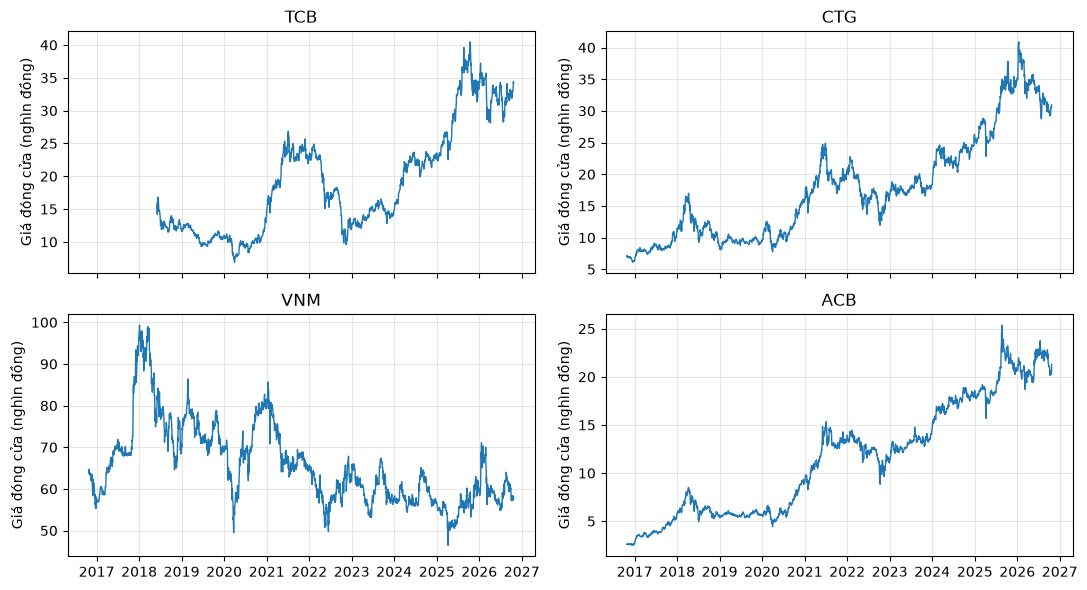

In [3]:
display(pd.concat({s: d[["close", "volume"]].describe().T for s, d in raw.items()}).round(1))

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for ax, (s, d) in zip(axes.ravel(), raw.items()):
    ax.plot(d.time, d.close, lw=1)
    ax.set_title(s)
    ax.set_ylabel("Giá đóng cửa (nghìn đồng)")
plt.tight_layout()
plt.show()

**Nhận xét:** TCB có dữ liệu từ 2018 nên ít nến (2.098) hơn ba mã còn lại (khoảng 2.495). Giá và khối lượng của các mã khác nhau nhiều lần (giá trung bình VNM 65,8 nghìn đồng, ACB 11,5 nghìn; khối lượng trung bình TCB 9,1 triệu, VNM 2,4 triệu cổ phiếu), nên đặc trưng phải ở dạng tỷ lệ (lợi suất, so với trung bình trượt), không dùng giá tuyệt đối.

## 3. Lợi suất ngày

,Trung bình (%),Độ lệch chuẩn (%),Skew,Kurtosis dư,Min (%),Max (%)
TCB,0.037,2.052,-0.284,2.574,-7.351,6.744
CTG,0.059,2.127,-0.165,2.267,-7.305,6.843
VNM,-0.004,1.507,0.176,3.814,-7.227,6.760
ACB,0.084,1.830,-0.169,4.377,-10.286,9.227


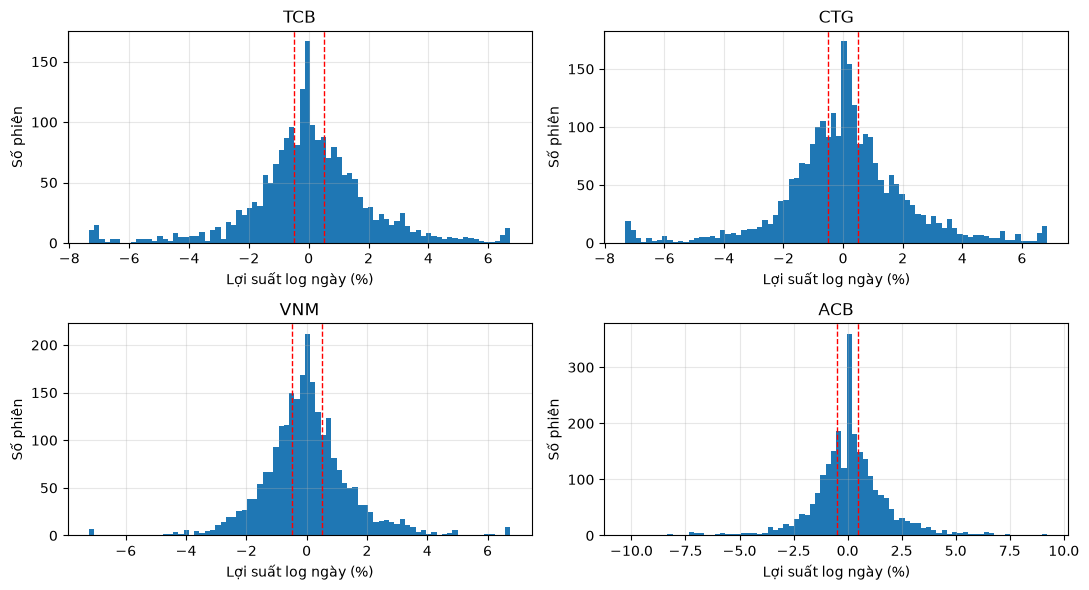

In [4]:
ret = {}
for s, d in raw.items():
    close = d.drop_duplicates("time", keep="last").set_index("time").close
    ret[s] = np.log(close / close.shift(1)).dropna()

display(pd.DataFrame({
    "Trung bình (%)": {s: r.mean() * 100 for s, r in ret.items()},
    "Độ lệch chuẩn (%)": {s: r.std() * 100 for s, r in ret.items()},
    "Skew": {s: r.skew() for s, r in ret.items()},
    "Kurtosis dư": {s: r.kurt() for s, r in ret.items()},
    "Min (%)": {s: r.min() * 100 for s, r in ret.items()},
    "Max (%)": {s: r.max() * 100 for s, r in ret.items()},
}).round(3))

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for ax, (s, r) in zip(axes.ravel(), ret.items()):
    ax.hist(r * 100, bins=80)
    ax.axvline(THETA * 100, color="r", ls="--", lw=1)
    ax.axvline(-THETA * 100, color="r", ls="--", lw=1)
    ax.set_title(s)
    ax.set_xlabel("Lợi suất log ngày (%)")
    ax.set_ylabel("Số phiên")
plt.tight_layout()
plt.show()

**Nhận xét:** Lợi suất trung bình mỗi ngày gần 0 (dưới 0,1%) trong khi độ lệch chuẩn 1,5 đến 2,1%, nên đoán hướng đi rất khó. Kurtosis dư từ 2,3 đến 4,4 cho thấy đuôi nặng: thỉnh thoảng có phiên biến động rất mạnh (cao nhất khoảng ±7%, riêng ACB đến −10,3%). Hai đường đỏ là ngưỡng ±θ của nhãn.

## 4. Phân bố nhãn

Nhãn là hướng đi của phiên kế tiếp: giảm nếu lợi suất < −θ, tăng nếu > θ, còn lại là ngang (θ = 0,5%).

,Giảm,Ngang,Tăng
TCB,34.4,29.7,35.8
CTG,35.8,28.0,36.1
VNM,32.8,37.0,30.2
ACB,31.2,34.4,34.4


,θ=0.2%,θ=0.3%,θ=0.5%,θ=1.0%
Tỷ lệ 'ngang' (%),,,,
TCB,14.0,20.2,29.7,51.2
CTG,12.8,18.5,28.0,49.8
VNM,17.9,24.1,37.0,61.7
ACB,16.9,22.9,34.4,57.7


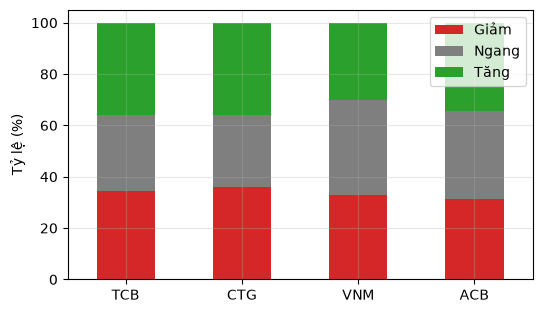

In [5]:
def class_share(r, theta):
    nxt = r.shift(-1).dropna()
    return pd.Series({"Giảm": (nxt < -theta).mean(), "Ngang": (nxt.abs() <= theta).mean(), "Tăng": (nxt > theta).mean()})


share = pd.DataFrame({s: class_share(r, THETA) for s, r in ret.items()}).T * 100
flat_by_theta = pd.DataFrame({f"θ={t * 100:.1f}%": {s: class_share(r, t)["Ngang"] * 100 for s, r in ret.items()} for t in (0.002, 0.003, 0.005, 0.01)})
display(share.round(1), flat_by_theta.round(1).rename_axis("Tỷ lệ 'ngang' (%)"))
share.plot(kind="bar", stacked=True, figsize=(6, 3.5), rot=0, color=["tab:red", "tab:gray", "tab:green"], ylabel="Tỷ lệ (%)")
plt.show()

**Nhận xét:** Với θ = 0,5%, ba lớp khá cân bằng (giảm 31 đến 36%, ngang 28 đến 37%, tăng 30 đến 36%), nên đoán bừa chỉ đúng khoảng 33% và cần dùng F1 macro thay vì chỉ Accuracy. Tăng θ làm lớp ngang phình ra (θ = 1% thì chiếm 50 đến 62%), vì vậy giữ θ = 0,5%.

## 5. Tự tương quan

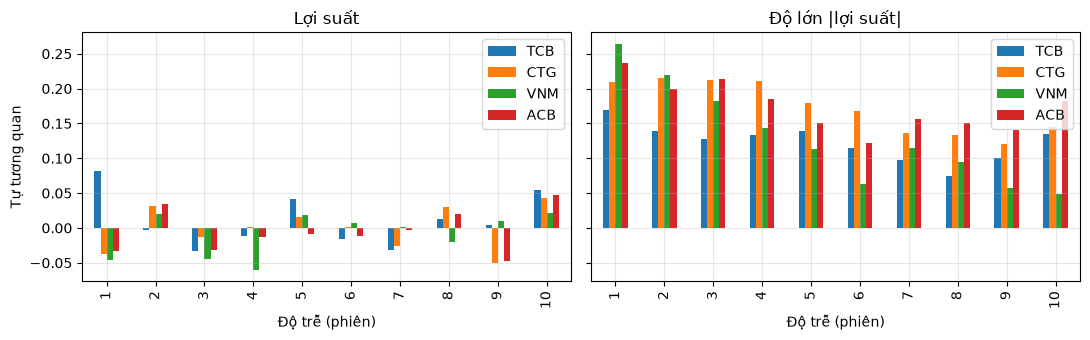

In [6]:
lags = range(1, 11)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
pd.DataFrame({s: [r.autocorr(l) for l in lags] for s, r in ret.items()}, index=lags).plot(kind="bar", ax=axes[0], title="Lợi suất")
pd.DataFrame({s: [r.abs().autocorr(l) for l in lags] for s, r in ret.items()}, index=lags).plot(kind="bar", ax=axes[1], title="Độ lớn |lợi suất|")
for ax in axes:
    ax.set_xlabel("Độ trễ (phiên)")
    ax.set_ylabel("Tự tương quan")
plt.tight_layout()
plt.show()

**Nhận xét:** Lợi suất gần như không tự tương quan (|ρ| ≤ 0,08 ở độ trễ 1), tức giá hôm qua hầu như không báo trước hướng hôm nay. Ngược lại độ lớn |lợi suất| tự tương quan dương rõ (0,17 đến 0,26 ở độ trễ 1, vẫn dương sau 10 phiên): biến động có tính cụm, ngày biến động mạnh hay kéo theo ngày biến động mạnh. Dự đoán độ lớn dễ hơn dự đoán hướng.

## 6. Đặc trưng và nhãn

Dùng `data/processed/1D` (25 đặc trưng). Chỉ để khảo sát: tương quan tính trên toàn bộ dữ liệu nên **không dùng để chọn đặc trưng** (tránh rò rỉ).

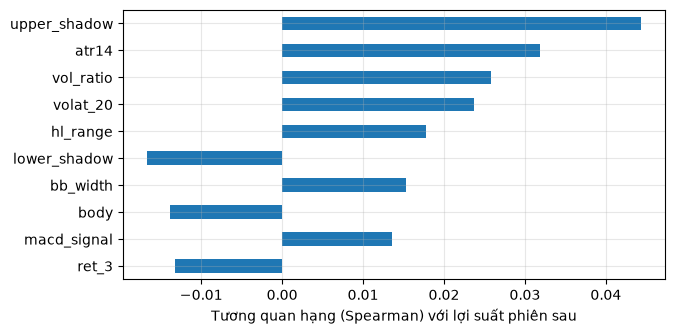

Cặp đặc trưng có |ρ| > 0,95: 5 / 300
Tương quan lớn nhất với lợi suất phiên sau: |ρ| = 0.044


In [7]:
from preprocess_data import feature_columns_for

features = list(feature_columns_for("1D"))
proc = pd.concat({s: pd.read_csv(ROOT / "data/processed/1D" / f"{s}.csv") for s in SYMBOLS}, names=["symbol"]).reset_index(level=0)

corr = proc[features].corrwith(proc["r_next"], method="spearman")
corr.reindex(corr.abs().sort_values().index)[-10:].plot(kind="barh", figsize=(7, 3.5), xlabel="Tương quan hạng (Spearman) với lợi suất phiên sau")
plt.show()

pairs = proc[features].corr().abs().where(np.triu(np.ones((len(features),) * 2, bool), 1)).stack().dropna()
print(f"Cặp đặc trưng có |ρ| > 0,95: {(pairs > 0.95).sum()} / {len(pairs)}")
print(f"Tương quan lớn nhất với lợi suất phiên sau: |ρ| = {corr.abs().max():.3f}")

**Nhận xét:**
1. Không đặc trưng nào tương quan đáng kể với lợi suất phiên sau: lớn nhất chỉ |ρ| = 0,044 (`upper_shadow`). Tín hiệu rất yếu nên khó đạt F1 cao.
2. Năm cặp đặc trưng gần như trùng nhau (|ρ| > 0,95), ví dụ `close_sma10` với `close_ema12`, `macd` với `macd_signal`. Với cây quyết định điều này không hại; với Logistic cần chuẩn hóa và phạt L2.
3. Các đặc trưng đứng đầu đều đo biến động và hình dạng nến (`upper_shadow`, `atr14`, `vol_ratio`, `volat_20`), không phải đà tăng giá.

## 7. Kết luận cho bước mô hình

- Ba lớp cân bằng với θ = 0,5%: dùng F1 macro, không chỉ Accuracy.
- Tín hiệu rất yếu (|ρ| ≤ 0,05 với lợi suất phiên sau, lợi suất gần như không tự tương quan): kỳ vọng thấp, so với baseline và báo cáo trung thực.
- Biến động có tính cụm, nên các đặc trưng biến động (`volat_*`, `atr14`) có lý do để dùng.
- Chia theo thời gian (walk-forward); scaler và chọn tham số chỉ khớp trên tập huấn luyện để không rò rỉ (checklist ở `docs/data-preprocess.md`).